In [14]:
import numpy as np
import matplotlib.pyplot as plt
import os
from utils import seir_modeling, seir_solver
from scipy.integrate import simpson

In [15]:
# Constants for SEIR model (copied from partD)
N = 2000
y0 = [1980, 15, 5, 0]
beta = 0.125*1e-3
gamma = 0.1
sigma = 0.25
mu = 0.005
dt = 0.1
days = 365

In [16]:
# problem i & ii
betas = np.linspace(0.05e-3, 0.25e-3, 100)
gammas = np.linspace(0.05, 0.25, 100)

peak_I = np.zeros((len(betas), len(gammas)))
total_inf = np.zeros((len(betas), len(gammas)))

for i, g in enumerate(gammas):
    for j, b in enumerate(betas): 
        t, y = seir_solver(seir_modeling, y0, days, dt, b, g, sigma, mu, N)
        S, E, I, R = y.T
        peak_I[j, i] = np.max(I)
        total_inf[j, i] = simpson(b * S * I, x=t)

print(peak_I)
print(total_inf)

[[ 230.73335972  208.4709776   187.73446842 ...    8.09836547
     8.06381148    8.03030299]
 [ 252.91562969  230.0654225   208.70033693 ...    8.12075401
     8.08611202    8.05165613]
 [ 274.6030287   251.24891496  229.34162198 ...    8.14322941
     8.10844447    8.07390086]
 ...
 [1031.04594643 1010.07370533  989.65530016 ...  150.89024
   147.59360393  144.35449718]
 [1033.67242858 1012.7523121   992.38147665 ...  153.6250211
   150.30801903  147.04845797]
 [1036.25392715 1015.38613181  995.06403243 ...  156.34669046
   153.0097823   149.73020392]]
[[2281.05731184 2190.408897   2099.21923978 ...   12.62551264
    12.46283187   12.30428455]
 [2373.03584811 2286.26845823 2199.59535898 ...   13.47354917
    13.29557051   13.1222255 ]
 [2457.60572182 2373.55280467 2290.14256094 ...   14.36614431
    14.17147944   13.98201056]
 ...
 [4854.46312866 4831.55877128 4808.6169155  ... 2724.75714103
  2695.60661889 2665.88027606]
 [4860.30915982 4837.59936798 4814.85432599 ... 2755.91442321
 

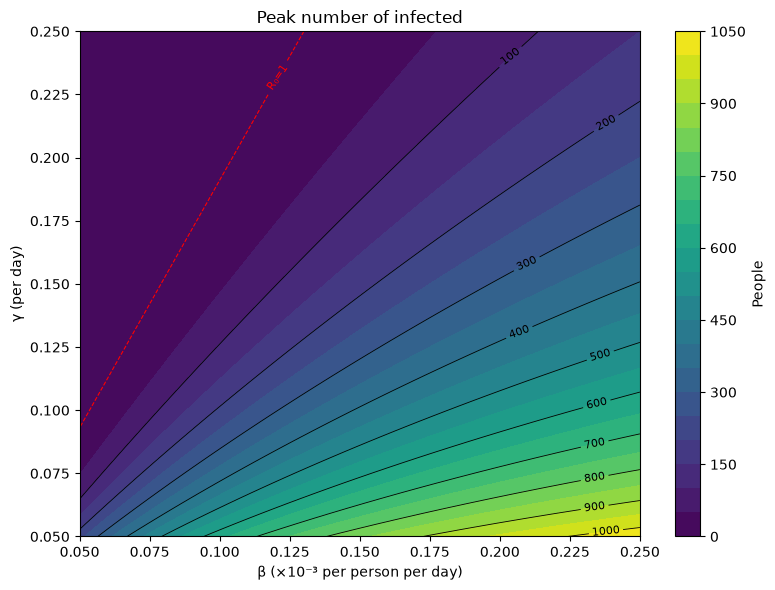

In [27]:
# contour plot for the peak number of infected

# build a grid of beta and gamma values
# multiply betas by 1e3 for better readability in the plot
Bg, Gg = np.meshgrid(betas*1e3, gammas)
# recalculate R0 grid based on the scaled beta values
R0_grid = (Bg * 1e-3) * N * sigma / ((sigma + mu) * (Gg + mu))

fig, ax = plt.subplots(figsize=(8, 6))

cf = ax.contourf(Bg, Gg, peak_I.T, levels=20, cmap="viridis")
cs = ax.contour(Bg, Gg, peak_I.T, levels=10, colors="k", linewidths=0.6)
ax.clabel(cs, inline=True, fontsize=8)
r0 = ax.contour(Bg, Gg, R0_grid, levels=[1], colors="r", linestyles='--', linewidths=0.8)
ax.clabel(r0, fontsize=8, fmt="R₀=1")

fig.colorbar(cf, ax=ax, label="People")
ax.set_xlabel("β (×10⁻³ per person per day)")
ax.set_ylabel("γ (per day)")
ax.set_title("Peak number of infected")
plt.tight_layout()
plt.savefig("figures/peak_infected_contour.png")
plt.show()

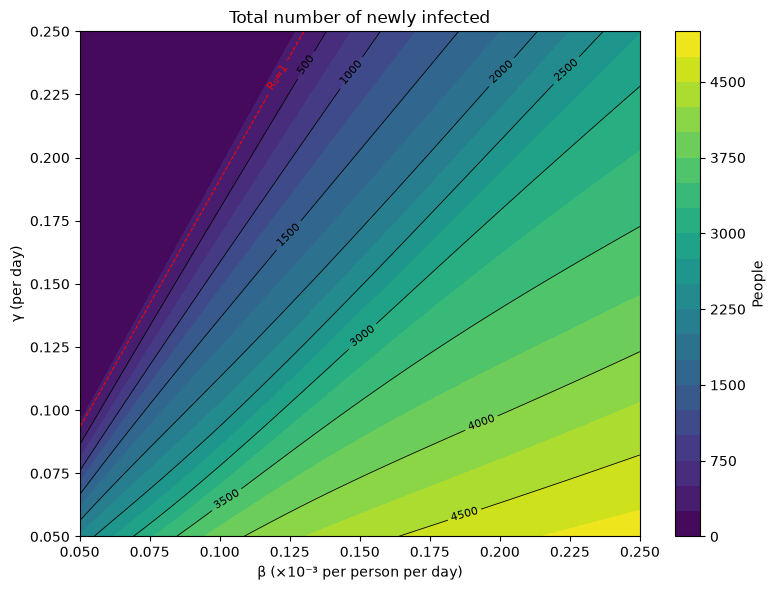

In [29]:
# contour plot for the total number of newly infected

# build a grid of beta and gamma values
# multiply betas by 1e3 for better readability in the plot
Bg, Gg = np.meshgrid(betas*1e3, gammas)
# recalculate R0 grid based on the scaled beta values
R0_grid = (Bg * 1e-3) * N * sigma / ((sigma + mu) * (Gg + mu))

fig, ax = plt.subplots(figsize=(8, 6))

cf = ax.contourf(Bg, Gg, total_inf.T, levels=20, cmap="viridis")
cs = ax.contour(Bg, Gg, total_inf.T, levels=10, colors="k", linewidths=0.6)
ax.clabel(cs, inline=True, fontsize=8)
r0 = ax.contour(Bg, Gg, R0_grid, levels=[1], colors="r", linestyles='--', linewidths=0.8)
ax.clabel(r0, fontsize=8, fmt="R₀=1")

fig.colorbar(cf, ax=ax, label="People")
ax.set_xlabel("β (×10⁻³ per person per day)")
ax.set_ylabel("γ (per day)")
ax.set_title("Total number of newly infected")
plt.tight_layout()
plt.savefig("figures/total_infected_contour.png")
plt.show()